In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/industrial-surface-defect-detection/public/sample_submission.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/train.csv
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/LZ46LTL6O2.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/13H1VTAZ42.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/G0DWU2GK1L.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/CVPHC0DT1P.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/90XJFQDL7G.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/3V8LZ56MOW.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/Y9EUV6TNP2.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/K76P42J0GK.jpg
/kaggle/input/competitions/industrial-surface-defect-detection/public/test/ZSS7THB1UM.jpg
/kaggle/input/comp

In [2]:
from pathlib import Path

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split

In [3]:
data_dir = Path("/kaggle/input/competitions/industrial-surface-defect-detection/public")

csv_path = data_dir / "train.csv"
train_image_dir = data_dir / "train"
test_image_dir = data_dir / "test"

In [4]:
print("CSV found:", csv_path.exists())
print("Train image folder found:", train_image_dir.exists())
print("Test image folder found:", test_image_dir.exists())

CSV found: True
Train image folder found: True
Test image folder found: True


In [5]:
train = pd.read_csv(csv_path)
image_id = train["image_id"].iloc[0]
image_path = data_dir / "train" / f"{image_id}.jpg"

In [6]:
with Image.open(image_path) as image:
    width, height = image.size

print(f"height: {height}")
print(f"width: {width}")

height: 128
width: 800


In [7]:
classes = sorted(train["defect_type"].unique())
print(classes)

['defect_a', 'defect_b', 'defect_c', 'defect_d']


In [8]:
classes = ["defect_a", "defect_b", "defect_c", "defect_d"]
height, width = 128, 800
seed = 42

In [9]:
print("Unique training images:")
train["image_id"].nunique()

Unique training images:


11393

In [10]:
train.head()

,image_id,defect_type,mask_rle,width,height
0,4S22I7SA34,defect_a,7255 6 7377 12 7505 12 7633 12 7762 11 7890 11...,800,128
1,4S22I7SA34,defect_b,NaN,800,128
2,4S22I7SA34,defect_c,NaN,800,128
3,4S22I7SA34,defect_d,NaN,800,128
4,DZ899111OE,defect_a,NaN,800,128


In [11]:
train.shape

(45572, 5)

In [12]:
print("Unexpected defect classes:", set(train["defect_type"]) - set(classes))

Unexpected defect classes: set()


In [13]:
print("Duplicate image/class rows:", train.duplicated(["image_id", "defect_type"]).sum())

Duplicate image/class rows: 0


In [14]:
rows_per_image = train.groupby("image_id").size()
print("Rows per image:", rows_per_image.unique())

Rows per image: [4]


In [15]:
classes = ["defect_a", "defect_b", "defect_c", "defect_d"]

train = pd.read_csv(csv_path, dtype=str, keep_default_na=False)
train["mask_rle"] = train["mask_rle"].str.strip()

mask_lookup = {}
for row in train.itertuples(index=False):
    key = (row.image_id, row.defect_type)
    mask_lookup[key] = row.mask_rle

images_data = []

for image_path in sorted(train_image_dir.glob("*.jpg")):
    image_id = image_path.stem
    rles = [mask_lookup.get((image_id, cls), "") for cls in classes]
    images_data.append([str(image_path), image_id, *rles])

images_df = pd.DataFrame(
    images_data,
    columns=["Image", "image_id"] + classes
)

images_df.head()

,Image,image_id,defect_a,defect_b,defect_c,defect_d
0,/kaggle/input/competitions/industrial-surface-...,000HAM628W,,,80866 7 80980 23 81094 40 81207 57 81325 69 81...,
1,/kaggle/input/competitions/industrial-surface-...,005VFS2MW4,,,,9869 2 9996 11 10124 15 10252 18 10379 24 1050...
2,/kaggle/input/competitions/industrial-surface-...,0070O9IJVX,,,,53469 9 53584 23 53703 33 53830 34 53958 35 54...
3,/kaggle/input/competitions/industrial-surface-...,00761I10TU,,,68395 28 68490 6 68497 4 68520 33 68615 20 686...,
4,/kaggle/input/competitions/industrial-surface-...,009DUJJXC1,,,,


In [16]:
defect_presence = images_df[classes].ne("").astype(int)

In [17]:
positive_counts = defect_presence.sum()
labels_per_image = defect_presence.sum(axis=1)

clean_images = (labels_per_image == 0).sum()
multi_label_images = (labels_per_image > 1).sum()

print("Positive images per class:")
print(positive_counts)
print("Clean images:", clean_images)
print("Multiple defect classes:", multi_label_images)

Positive images per class:
defect_a    1081
defect_b     313
defect_c    4100
defect_d    1707
dtype: int64
Clean images: 5516
Multiple defect classes: 1198


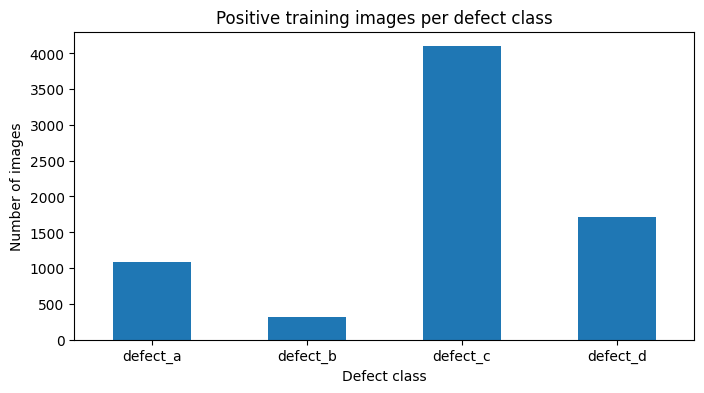

In [18]:
plt.figure(figsize=(8, 4))
positive_counts.plot(kind="bar")
plt.title("Positive training images per defect class")
plt.ylabel("Number of images")
plt.xlabel("Defect class")
plt.xticks(rotation=0)
plt.show()

In [19]:
image_table = defect_presence.copy()

image_table["label_combo"] = defect_presence.apply(
    lambda row: "+".join(row[row == 1].index) if row.sum() > 0 else "clean",
    axis=1
)

combination_counts = image_table["label_combo"].value_counts()

print("Unique combinations:", len(combination_counts))
display(combination_counts)

Unique combinations: 15


label_combo
clean                         5516
defect_c                      3105
defect_d                       822
defect_a                       601
defect_c+defect_d              598
defect_a+defect_c              215
defect_b                       151
defect_a+defect_d              136
defect_a+defect_c+defect_d      87
defect_b+defect_c               67
defect_b+defect_d               33
defect_a+defect_b               23
defect_b+defect_c+defect_d      20
defect_a+defect_b+defect_d      11
defect_a+defect_b+defect_c       8
Name: count, dtype: int64

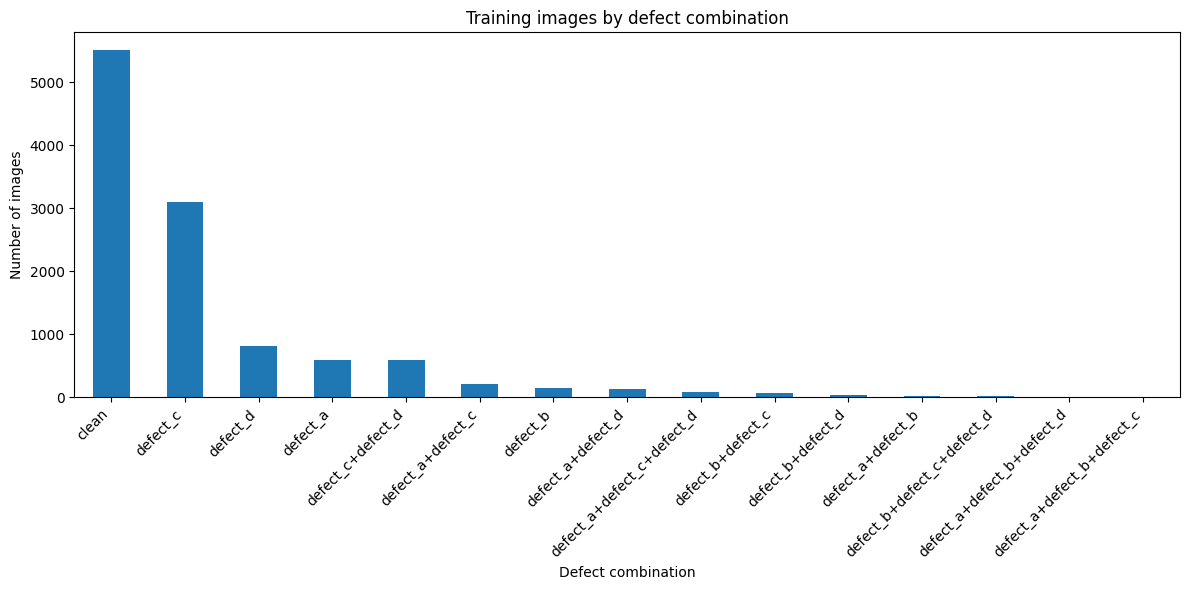

In [20]:
combination_counts.plot(kind="bar", figsize=(12, 6))
plt.title("Training images by defect combination")
plt.ylabel("Number of images")
plt.xlabel("Defect combination")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

## dataset creation

In [21]:
import cv2
import torch
from torch.utils.data import Dataset

In [22]:
class SurfaceDataset(Dataset):
    def __init__(self, images_df):
        self.images_df = images_df.reset_index(drop=True)

    def __len__(self):
        return len(self.images_df)

    def __getitem__(self, index):
        row = self.images_df.iloc[index]

        with Image.open(row["Image"]) as image_file:
            image = image_file.convert("RGB")
            image = np.array(image, dtype=np.float32) / 255.0

        image = torch.tensor(image).permute(2, 0, 1)

        masks = []

        for cls in classes:
            flat_mask = np.zeros(height * width, dtype=np.uint8)
            rle = str(row[cls]).strip()

            if rle != "":
                numbers = [int(value) for value in rle.split()]

                for i in range(0, len(numbers), 2):
                    start = numbers[i] - 1  
                    length = numbers[i + 1]
                    end = min(start + length, height * width)
                    flat_mask[start:end] = 1

            mask = flat_mask.reshape((height, width), order="F")
            masks.append(mask)

        masks = torch.tensor(np.array(masks), dtype=torch.float32)

        return image, masks

In [23]:
train_dataset = SurfaceDataset(images_df)

image, masks = train_dataset[0]

print("Number of training images:", len(train_dataset))
print("Image shape:", image.shape)
print("Masks shape:", masks.shape)

Number of training images: 11393
Image shape: torch.Size([3, 128, 800])
Masks shape: torch.Size([4, 128, 800])


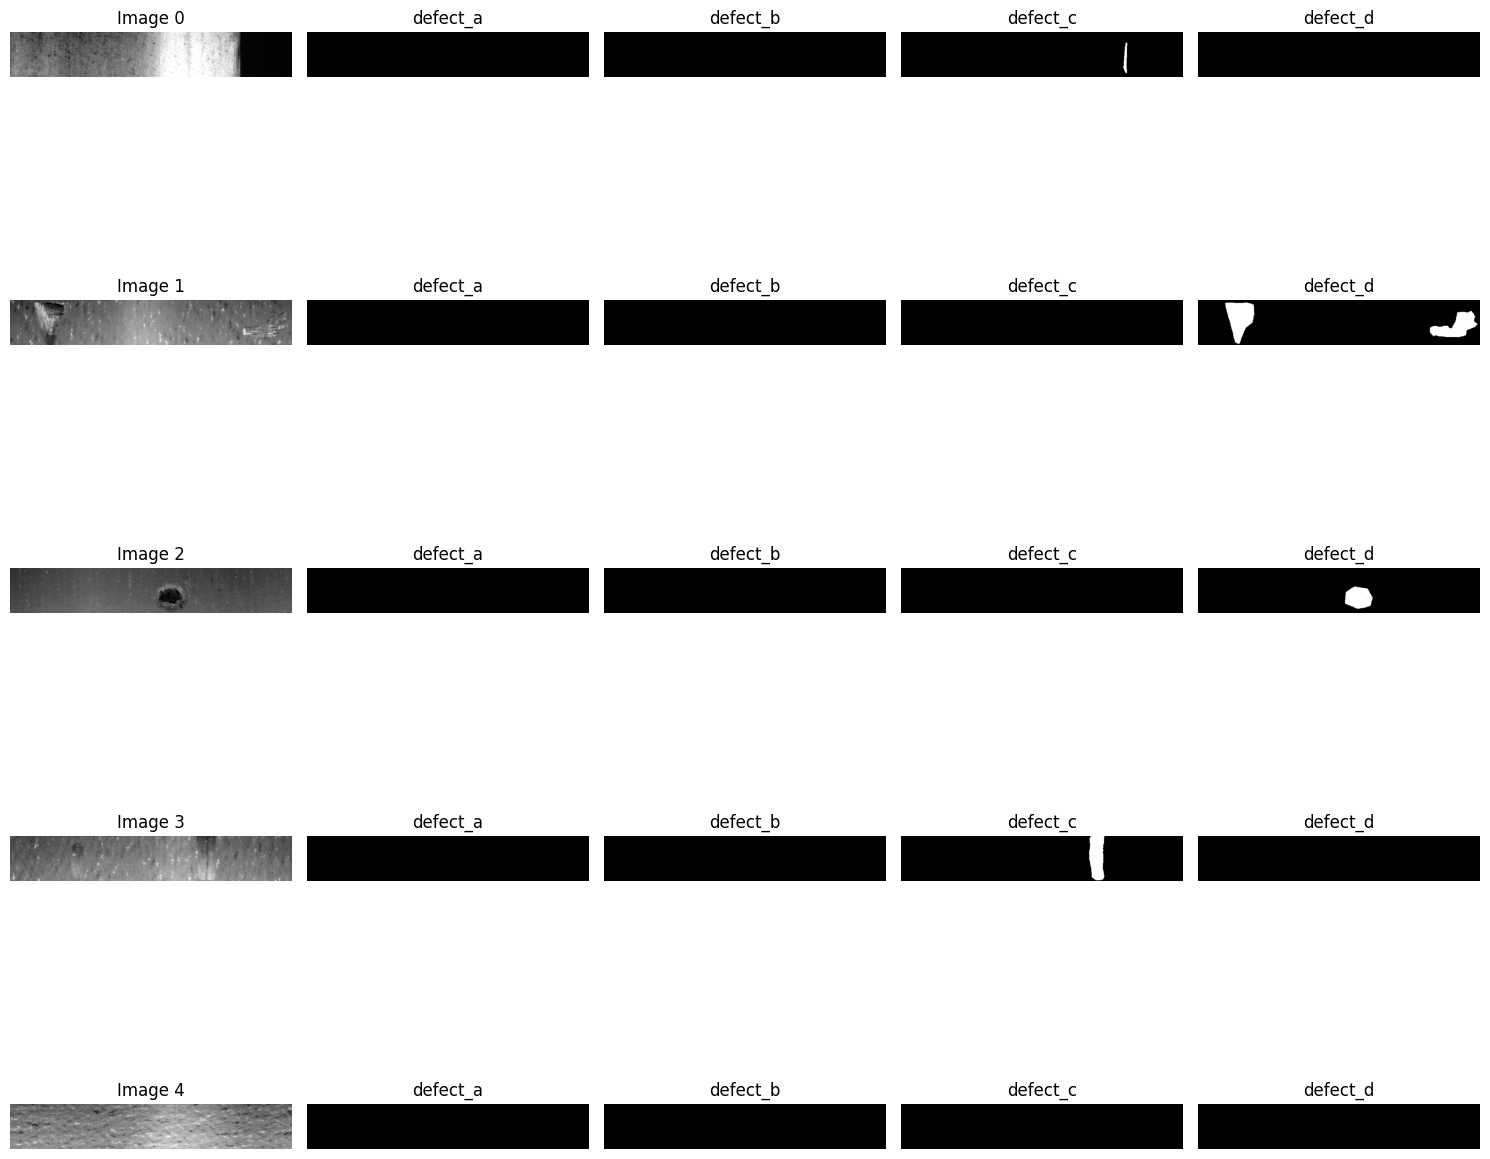

In [24]:
def plot_surface_images(indices):
    indices = list(indices)
    nrows = len(indices)

    fig, axes = plt.subplots(
        nrows,
        len(classes) + 1,
        figsize=(15, nrows * 3),
        squeeze=False
    )

    for row_index, sample_index in enumerate(indices):
        image, masks = train_dataset[sample_index]

        axes[row_index, 0].imshow(image.permute(1, 2, 0))
        axes[row_index, 0].set_title(f"Image {sample_index}")
        axes[row_index, 0].axis("off")

        for class_index, class_name in enumerate(classes):
            axes[row_index, class_index + 1].imshow(
                masks[class_index],
                cmap="gray",
                vmin=0,
                vmax=1
            )
            axes[row_index, class_index + 1].set_title(class_name)
            axes[row_index, class_index + 1].axis("off")

    plt.tight_layout()
    plt.show()


plot_surface_images(range(5))

In [25]:
def get_combination(row):
    present_classes = [cls for cls in classes if row[cls] != ""]
    return "+".join(present_classes) if present_classes else "clean"


images_df["label_combo"] = images_df.apply(get_combination, axis=1)

print("Number of combinations:", images_df["label_combo"].nunique())
print("\nImages per combination:")
print(images_df["label_combo"].value_counts().sort_index())

Number of combinations: 15

Images per combination:
label_combo
clean                         5516
defect_a                       601
defect_a+defect_b               23
defect_a+defect_b+defect_c       8
defect_a+defect_b+defect_d      11
defect_a+defect_c              215
defect_a+defect_c+defect_d      87
defect_a+defect_d              136
defect_b                       151
defect_b+defect_c               67
defect_b+defect_c+defect_d      20
defect_b+defect_d               33
defect_c                      3105
defect_c+defect_d              598
defect_d                       822
Name: count, dtype: int64


In [26]:
train_df, val_df = train_test_split(
    images_df,
    test_size=0.20,
    random_state=42,
    stratify=images_df["label_combo"]
)

train_dataset = SurfaceDataset(train_df)
val_dataset = SurfaceDataset(val_df)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))

Training images: 9114
Validation images: 2279


## baseline UNet

In [27]:
from torch import nn

In [28]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()

        self.net = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),

            nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
        )

    def forward(self, x):
        return self.net(x)


class BaselineUNet(nn.Module):
    def __init__(self, num_classes=4):
        super().__init__()

        # Encoder: extract image features
        self.en1 = DoubleConv(3, 64)
        self.en2 = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(64, 128)
        )
        self.en3 = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(128, 256)
        )

        # Middle of the U-Net
        self.bottleneck = nn.Sequential(
            nn.MaxPool2d(2),
            DoubleConv(256, 512)
        )

        # Decoder: restore image resolution and combine encoder features
        self.de1 = nn.ConvTranspose2d(512, 256, kernel_size=2, stride=2)
        self.conv_de1 = DoubleConv(512, 256)

        self.de2 = nn.ConvTranspose2d(256, 128, kernel_size=2, stride=2)
        self.conv_de2 = DoubleConv(256, 128)

        self.de3 = nn.ConvTranspose2d(128, 64, kernel_size=2, stride=2)
        self.conv_de3 = DoubleConv(128, 64)

        # One output channel for each defect class
        self.out = nn.Conv2d(64, num_classes, kernel_size=1)

    def forward(self, x):
        x1 = self.en1(x)
        x2 = self.en2(x1)
        x3 = self.en3(x2)

        b = self.bottleneck(x3)

        d1 = self.de1(b)
        d1 = self.conv_de1(torch.cat([d1, x3], dim=1))

        d2 = self.de2(d1)
        d2 = self.conv_de2(torch.cat([d2, x2], dim=1))

        d3 = self.de3(d2)
        d3 = self.conv_de3(torch.cat([d3, x1], dim=1))

        # Returns raw logits for the four defect classes
        return self.out(d3)


model = BaselineUNet(num_classes=len(classes))

In [29]:
class DiceLoss(nn.Module):
    def __init__(self, smooth=1.0):
        super().__init__()
        self.smooth = smooth

    def forward(self, logits, targets):
        probs = torch.sigmoid(logits)

        # Keep batch and class dimensions; flatten only height and width
        probs = probs.flatten(start_dim=2)
        targets = targets.flatten(start_dim=2)

        intersection = (probs * targets).sum(dim=2)
        total = probs.sum(dim=2) + targets.sum(dim=2)

        dice = (2.0 * intersection + self.smooth) / (
            total + self.smooth
        )

        return (1.0 - dice).mean()


class BCEDiceLoss(nn.Module):
    def __init__(self, bce_weight=0.5, smooth=1.0):
        super().__init__()
        self.bce_logits = nn.BCEWithLogitsLoss()
        self.dice = DiceLoss(smooth=smooth)
        self.bce_weight = bce_weight

    def forward(self, logits, targets):
        bce_loss = self.bce_logits(logits, targets)
        dice_loss = self.dice(logits, targets)

        # The two weights add up to 1
        return (
            self.bce_weight * bce_loss
            + (1.0 - self.bce_weight) * dice_loss
        )


def compute_binary_dice(logits, targets, threshold=0.5, eps=1e-7):
    """Return Dice for each image-class pair and mark pairs with defects."""

    probs = torch.sigmoid(logits)
    predictions = (probs >= threshold).float()

    # Shape becomes [batch, 4, height * width]
    predictions = predictions.flatten(start_dim=2)
    targets = targets.flatten(start_dim=2)

    intersection = (predictions * targets).sum(dim=2)
    cardinality = predictions.sum(dim=2) + targets.sum(dim=2)

    dice = (2.0 * intersection + eps) / (cardinality + eps)

    # If both masks are empty, Dice is 1
    dice[cardinality == 0] = 1.0

    # True where that image has this defect class
    positive_pairs = targets.sum(dim=2) > 0

    return dice, positive_pairs

In [30]:
from kaggle_secrets import UserSecretsClient
user_secrets = UserSecretsClient()
secret_value_0 = user_secrets.get_secret("wandb_api_key")


In [31]:
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader
import torch.optim as optim
from tqdm.auto import tqdm
import os
from kaggle_secrets import UserSecretsClient
import wandb

user_secrets = UserSecretsClient()
wandb_api_key = user_secrets.get_secret("WANDB_API_KEY")
os.environ['WANDB_API_KEY'] = wandb_api_key

wandb.login(key=wandb_api_key)

wandb: WARNING If you're specifying your api key in code, ensure this code is not shared publicly.
wandb: WARNING Consider setting the WANDB_API_KEY environment variable, or running `wandb login` from the command line.
wandb: [wandb.login()] Using explicit session credentials for https://api.wandb.ai.
wandb: No netrc file found, creating one.
wandb: Appending key for api.wandb.ai to your netrc file: /root/.netrc
wandb: W&B API key is configured. Use `wandb login --relogin` to force relogin


True

In [32]:
import wandb

In [33]:
DEVICE = torch.device(
    "cuda" if torch.cuda.is_available()
    else "mps" if torch.backends.mps.is_available()
    else "cpu"
)

TRAINING_CONFIG = {
    "BATCH_SIZE": 4,
    "LR": 3e-4,
    "EPOCHS": 5,
    "DEVICE": str(DEVICE),
    "ARCHITECTURE": "BaselineUNet",
    "NUM_CLASSES": len(classes),
    "IMAGE_HEIGHT": height,
    "IMAGE_WIDTH": width,
}

run = wandb.init(
    project="surfaceguard-ai",
    name="baseline-unet-run1",
    config=TRAINING_CONFIG,
)

print("Training on:", DEVICE)

wandb: Tracking run with wandb version 0.28.1
wandb: Run data is saved locally in /kaggle/working/wandb/run-20261026_125115-vemb3cqv
wandb: Run `wandb offline` to turn off syncing.
wandb: Syncing run baseline-unet-run1
wandb: ⭐️ View project at https://wandb.ai/23f2002932-indian-institute-of-technology-madras/surfaceguard-ai
wandb: 🚀 View run at https://wandb.ai/23f2002932-indian-institute-of-technology-madras/surfaceguard-ai/runs/vemb3cqv


Training on: cuda


## model setup

In [34]:
from torch.utils.data import DataLoader
import torch.optim as optim

In [35]:
DEVICE = torch.device(TRAINING_CONFIG["DEVICE"])

# Four output channels: one for each defect class
model = BaselineUNet(num_classes=len(classes)).to(DEVICE)

# Create dataloaders from the datasets made in the split cell
train_loader = DataLoader(
    train_dataset,
    batch_size=TRAINING_CONFIG["BATCH_SIZE"],
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=TRAINING_CONFIG["BATCH_SIZE"],
    shuffle=False,
    num_workers=0,
    pin_memory=False
)
# Optimizer
optimizer = optim.AdamW(
    model.parameters(),
    lr=TRAINING_CONFIG["LR"]
)

# Combined BCE and Dice loss
criterion = BCEDiceLoss(bce_weight=0.5, smooth=1.0)

print("Model device:", DEVICE)
print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))

Model device: cuda
Training batches: 2279
Validation batches: 570


In [36]:
def save_and_upload_model(model, filepath="best_surfaceguard_unet.pth", metadata=None):
    # Save the model weights locally
    torch.save(model.state_dict(), filepath)

    # Create a W&B artifact for this project
    artifact = wandb.Artifact(
        name="surfaceguard-baseline-unet",
        type="model",
        description="Baseline U-Net weights for industrial surface defect segmentation",
        metadata=metadata or {}
    )

    artifact.add_file(filepath)
    run.log_artifact(artifact)

    print(f"Saved and logged model artifact: {filepath}")

In [37]:
from tqdm.auto import tqdm

In [38]:
BEST_MODEL_PATH = Path("best_surfaceguard_unet.pth")
best_val_loss = float("inf")
global_step = 0

for epoch in range(TRAINING_CONFIG["EPOCHS"]):
    # ----- Training -----
    model.train()
    train_loss_total = 0.0

    train_progress = tqdm(
        train_loader,
        desc=f"Epoch {epoch + 1}/{TRAINING_CONFIG['EPOCHS']} - training"
    )

    for images, masks in train_progress:
        images = images.to(DEVICE)
        masks = masks.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)

        logits = model(images)
        loss = criterion(logits, masks)

        loss.backward()
        optimizer.step()

        train_loss_total += loss.item()
        global_step += 1

        train_progress.set_postfix(loss=f"{loss.item():.4f}")

    average_train_loss = train_loss_total / len(train_loader)

    # ----- Validation -----
    model.eval()
    val_loss_total = 0.0
    val_image_count = 0
    all_pair_dices = []
    foreground_dices = []

    with torch.no_grad():
        for images, masks in tqdm(
            val_loader,
            desc=f"Epoch {epoch + 1}/{TRAINING_CONFIG['EPOCHS']} - validation"
        ):
            images = images.to(DEVICE)
            masks = masks.to(DEVICE)

            logits = model(images)
            loss = criterion(logits, masks)

            val_loss_total += loss.item() * len(images)
            val_image_count += len(images)

            # Dice for every image-class pair, using threshold 0.5
            dices, positive_pairs = compute_binary_dice(
                logits,
                masks,
                threshold=0.5
            )

            all_pair_dices.extend(dices.cpu().reshape(-1).tolist())

            if positive_pairs.any():
                foreground_dices.extend(
                    dices[positive_pairs].cpu().tolist()
                )

    average_val_loss = val_loss_total / val_image_count
    mean_pair_dice = float(np.mean(all_pair_dices))
    mean_foreground_dice = (
        float(np.mean(foreground_dices))
        if foreground_dices
        else 0.0
    )

    print(
        f"Epoch {epoch + 1}: "
        f"train loss={average_train_loss:.4f}, "
        f"validation loss={average_val_loss:.4f}, "
        f"mean pair Dice={mean_pair_dice:.4f}, "
        f"foreground Dice={mean_foreground_dice:.4f}"
    )

    # Log the epoch results to W&B
    run.log({
        "epoch": epoch + 1,
        "train/loss": average_train_loss,
        "val/loss": average_val_loss,
        "val/mean_pair_dice": mean_pair_dice,
        "val/foreground_dice": mean_foreground_dice,
        "global_step": global_step,
    })

    # Save the model when validation loss improves
    if average_val_loss < best_val_loss:
        best_val_loss = average_val_loss
        torch.save(model.state_dict(), BEST_MODEL_PATH)
        print(f"Saved best model: {BEST_MODEL_PATH}")

# Load the best checkpoint and upload it to W&B
model.load_state_dict(
    torch.load(BEST_MODEL_PATH, map_location=DEVICE)
)

save_and_upload_model(
    model,
    filepath=str(BEST_MODEL_PATH),
    metadata={
        "best_validation_loss": best_val_loss,
        "architecture": "BaselineUNet",
        "classes": classes,
        "height": height,
        "width": width,
    }
)

Epoch 1/5 - training:   0%|          | 0/2279 [00:00<?, ?it/s]

Epoch 1/5 - validation:   0%|          | 0/570 [00:00<?, ?it/s]

Epoch 1: train loss=0.5307, validation loss=0.4971, mean pair Dice=0.6542, foreground Dice=0.2508
Saved best model: best_surfaceguard_unet.pth


Epoch 2/5 - training:   0%|          | 0/2279 [00:00<?, ?it/s]

Epoch 2/5 - validation:   0%|          | 0/570 [00:00<?, ?it/s]

...

Epoch 4/5 - validation:   0%|          | 0/570 [00:00<?, ?it/s]

Epoch 4: train loss=0.1430, validation loss=0.1346, mean pair Dice=0.8419, foreground Dice=0.0000
Saved best model: best_surfaceguard_unet.pth


Epoch 5/5 - training:   0%|          | 0/2279 [00:00<?, ?it/s]

Epoch 5/5 - validation:   0%|          | 0/570 [00:00<?, ?it/s]

Epoch 5: train loss=0.1357, validation loss=0.1383, mean pair Dice=0.8419, foreground Dice=0.0000
Saved and logged model artifact: best_surfaceguard_unet.pth


In [39]:
artifact = run.use_artifact("surfaceguard-baseline-unet:latest",type="model")

artifact_dir = artifact.download()
print("Downloaded to:", artifact_dir)

wandb:   1 of 1 files downloaded.  


Downloaded to: /kaggle/working/artifacts/surfaceguard-baseline-unet:v4


In [40]:
class SurfaceTestDataset(Dataset):
    def __init__(self, test_image_dir):
        self.image_paths = sorted(test_image_dir.glob("*.jpg"))

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, index):
        image_path = self.image_paths[index]

        with Image.open(image_path) as image_file:
            image = image_file.convert("RGB")
            image = np.array(image, dtype=np.float32) / 255.0

        image = torch.tensor(image).permute(2, 0, 1)
        return image, image_path.stem


def rle_encode(mask):
    pixels = np.asarray(mask, dtype=np.uint8).reshape(-1, order="F")

    if pixels.sum() == 0:
        return ""

    padded = np.concatenate(([0], pixels, [0]))
    changes = np.diff(padded)
    starts = np.where(changes == 1)[0] + 1
    ends = np.where(changes == -1)[0] + 1

    runs = []
    for start, end in zip(starts, ends):
        runs.extend([str(start), str(end - start)])

    return " ".join(runs)


test_image_dir = data_dir / "test"
test_dataset = SurfaceTestDataset(test_image_dir)

test_loader = DataLoader(
    test_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0
)

predicted_rles = {}
threshold = 0.9

model.eval()

with torch.no_grad():
    for images, image_ids in test_loader:
        images = images.to(DEVICE)
        logits = model(images)
        predictions = (torch.sigmoid(logits) >= threshold).cpu().numpy()

        for image_index, image_id in enumerate(image_ids):
            for class_index, cls in enumerate(classes):
                predicted_rles[(image_id, cls)] = rle_encode(
                    predictions[image_index, class_index]
                )

print("Test images:", len(test_dataset))
print("Predictions created:", len(predicted_rles))

Test images: 3000
Predictions created: 12000


In [41]:
sample_path = (
    "/kaggle/input/competitions/"
    "industrial-surface-defect-detection/public/sample_submission.csv"
)

submission = pd.read_csv(
    sample_path,
    dtype=str,
    keep_default_na=False
)

submission["mask_rle"] = [
    predicted_rles.get((str(image_id), str(defect_type)), "")
    for image_id, defect_type in zip(
        submission["image_id"],
        submission["defect_type"]
    )
]

# Kaggle treats empty fields as null, so use a space for empty masks
submission["mask_rle"] = (
    submission["mask_rle"].replace("", " ").fillna(" ")
)

output_path = "/kaggle/working/submission.csv"
submission.to_csv(output_path, index=False)

print("Columns:", submission.columns.tolist())
print("Rows:", len(submission))
print("Null values:", submission.isna().sum().sum())
print("Saved file:", output_path)

submission.head()

Columns: ['ID', 'image_id', 'defect_type', 'mask_rle']
Rows: 12000
Null values: 0
Saved file: /kaggle/working/submission.csv


,ID,image_id,defect_type,mask_rle
0,1,WAFNKCRR7Q,defect_a,
1,2,WAFNKCRR7Q,defect_b,
2,3,WAFNKCRR7Q,defect_c,
3,4,WAFNKCRR7Q,defect_d,
4,5,YZXKEWSUDD,defect_a,


In [42]:
sample_path = (
    "/kaggle/input/competitions/"
    "industrial-surface-defect-detection/public/sample_submission.csv"
)
submission_path = "/kaggle/working/submission.csv"

sample = pd.read_csv(sample_path, dtype=str, keep_default_na=False)
check = pd.read_csv(submission_path, dtype=str, keep_default_na=False)

# Check the required columns and their order
assert check.columns.tolist() == sample.columns.tolist(), "Column names/order do not match"
assert len(check) == len(sample), "Submission has the wrong number of rows"

# Check every image-class pair appears once
pair_columns = ["image_id", "defect_type"]
assert not check.duplicated(pair_columns).any(), "Duplicate image-class rows"
assert set(map(tuple, check[pair_columns].values)) == set(
    map(tuple, sample[pair_columns].values)
), "Image-class pairs do not match the sample"

# Check for actual missing values
assert check.isna().sum().sum() == 0, "Submission contains null values"

# Check each non-empty RLE has valid start/length pairs within 128 × 800
canvas_size = 128 * 800

for row_number, rle in enumerate(check["mask_rle"], start=1):
    if rle.strip() == "":
        continue  # An empty mask is allowed

    numbers = [int(value) for value in rle.split()]
    assert len(numbers) % 2 == 0, f"Odd number of RLE values in row {row_number}"

    starts = numbers[0::2]
    lengths = numbers[1::2]

    assert all(start >= 1 for start in starts), f"Invalid RLE start in row {row_number}"
    assert all(length > 0 for length in lengths), f"Invalid RLE length in row {row_number}"
    assert all(
        start + length - 1 <= canvas_size
        for start, length in zip(starts, lengths)
    ), f"RLE exceeds image size in row {row_number}"

print("Submission format checks passed.")
print("Rows:", len(check))
print("Non-empty masks:", (check["mask_rle"].str.strip() != "").sum())

Submission format checks passed.
Rows: 12000
Non-empty masks: 0
